<a href="https://colab.research.google.com/github/TejasShrestha/DATA201-labs/blob/main/Assignments/Week_9_HW_Decision_Tree_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 9 HW: Decision Tree Assignment**

## **Part 1: Build a Classification Tree**

### **1**

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [3]:
from ISLP import load_data
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [4]:
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(carseats['HighSales'].value_counts())
carseats.head()

HighSales
0    236
1    164
Name: count, dtype: int64


,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,HighSales
0,138,73,11,276,120,Bad,42,17,Yes,Yes,1
1,111,48,16,260,83,Good,65,10,Yes,Yes,1
2,113,35,10,269,80,Medium,59,12,Yes,Yes,1
3,117,100,4,466,97,Medium,55,14,Yes,Yes,0
4,141,64,3,340,128,Bad,38,13,Yes,No,0


### **2 & 3**

In [5]:
# One-hot encode the two text columns using pd this time!
X = pd.get_dummies(carseats.drop(columns=['HighSales']), columns=['ShelveLoc', 'US', 'Urban']).astype(int)
y = carseats['HighSales']

# Hold out 30% of patients for testing. stratify keeps the class mix similar in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=5, stratify=y)


print(X_train.shape, X_test.shape)

#you can check your sets (X_train, X_test,...)
X_train.head()

(280, 14) (120, 14)


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,US_No,US_Yes,Urban_No,Urban_Yes
97,161,82,5,287,129,33,16,1,0,0,0,1,0,1
375,132,46,4,206,124,73,11,0,0,1,1,0,0,1
169,104,41,15,492,77,73,18,0,1,0,0,1,0,1
47,126,98,0,173,108,55,16,1,0,0,1,0,0,1
306,131,32,1,85,133,48,12,0,0,1,0,1,0,1


### **4 & 5**

*   Train accuracy: 0.793
*   Test accuracy:  0.675

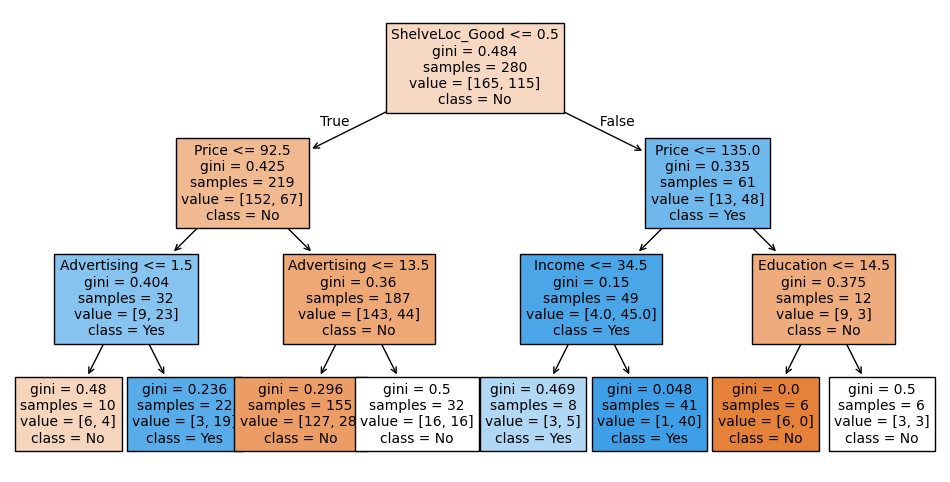

Train accuracy: 0.793
Test accuracy:  0.675


In [31]:
tree = DecisionTreeClassifier(max_depth=3, random_state=5)
tree.fit(X_train, y_train)

#figure's size
plt.figure(figsize=(12, 6))

plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'],
          filled=True,
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree.score(X_test, y_test), 3))

## **Part 2: Investigate Overfitting**

### **1 & 2**

In [27]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=5),
    param_grid={'max_depth': [1,2,3,4,5,6,7,8,9,10,11]},
    cv=5)

grid.fit(X_train, y_train)

print('Best settings:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3))
print('Test accuracy of best model:', round(grid.score(X_test, y_test), 3))

Best settings: {'max_depth': 2}
Best CV accuracy: 0.739
Test accuracy of best model: 0.717


### **3**

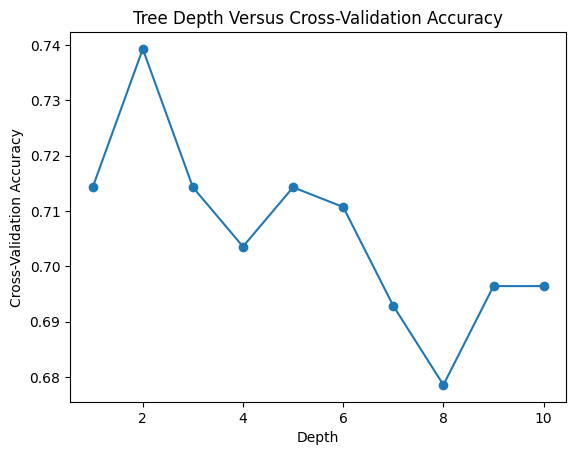

In [19]:
depths = range(1, 11)
cv_accuracy = []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=5)
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='accuracy')
    cv_accuracy.append(scores.mean())

plt.plot(depths, cv_accuracy, marker='o')
plt.xlabel('Depth')
plt.ylabel('Cross-Validation Accuracy')
plt.title('Tree Depth Versus Cross-Validation Accuracy')
plt.show()

### **4**

The best depth based on cross-validation is 2 as shown in the graph and the Best Settings is when max depth is 2. The CV accuracy is 0.739 at depth 2.

### **5**

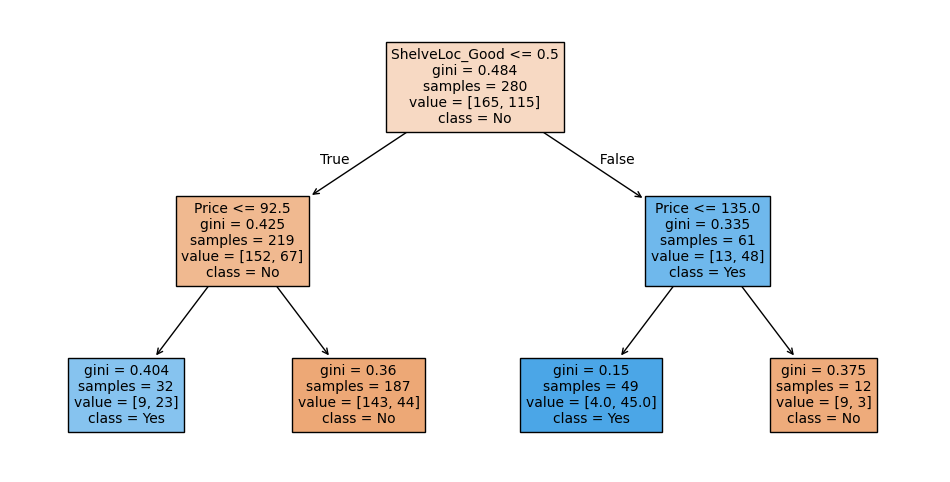

Train accuracy: 0.786
Test accuracy:  0.717


In [35]:
tree2 = DecisionTreeClassifier(max_depth=2, random_state=5)
tree2.fit(X_train, y_train)

#figure's size
plt.figure(figsize=(12, 6))

plot_tree(tree2,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'],
          filled=True,
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree2.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree2.score(X_test, y_test), 3))

In [28]:
print('Test accuracy of Max Depth 2:', round(grid.score(X_test, y_test), 3))

Test accuracy of Max Depth 2: 0.717


After training a final tree using the best depth we found of 2, the test accuracy is 71.7% for that maximum depth. There are less leaves in the tree, simplifying the tree overall.

# **Part 3: Answer the Following Questions**

### **1.**

In [30]:
# Get the feature and threshold chosen at the root
feat = X_train.columns[tree.tree_.feature[0]]
thr = tree.tree_.threshold[0]

print('Root split:', feat, '<=', thr)

Root split: ShelveLoc_Good <= 0.5


The first predictor selected for the root split was ShelveLoc_Good. The threshold is 0.5. This tells us that shelf location is an important factor in predicting sales, and stores with good shelf locations are more likely to have higher sales.

### **2.**
According to my cross-validation, a maximum depth of 2 performed the best with the highest CV accuracy of 73.9%. We should use cross-validation rather than test accuracy to choose the depth because cross-validation looks at the model in many different training and validation splits. This helps us choose the best model possible without using the test data which would inflict bias.
### **3.**
Increasing tree depth does not always improve cross-validation accuracy. Looking at the graph I created, CV accuracy was highest at a depth of 2. Increasing the depth caused the CV score to plummet severely with the lowest in the range being at depth 8. This can make the data too complex for the model.

# **Lab Wrap Up Questions**

Answer in your own words in a text cell.

1. What does a leaf predict in a classification tree? In a regression tree?

A leaf in a classification tree predicts a class or category. In a regression tree, a leaf predicts the mean of the training responses in it.

2. Why did the full tree reach 100% training accuracy but do worse on the test set?

It did worse on the test set due to overfitting from the model. Since there is no limit, the tree keeps on splitting until every leaf is pure.

3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?

Two ways to limit tree complexity are by using maximum tree depth or using minimum number of samples. Cross-validation helped me tune the maximum depth to help find the best model depth.

4. Why do we not need to scale features before fitting a tree?

We do not need to sacle features before fitting a tree because trees only compare a feature to a threshold, so sacling is not necessary.

5. A teammate says "`Age` has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

This claim is wrong because age may still be an important factor but it may just ahve orverlapping data with other features already being used.

6. Name one strength and one weakness of a single decision tree that you saw in this lab.

One strength of a decision tree is that it is easy to interpret and visualize through the graphs. One weakness is that it can overfit the training data which can cause flaws in accuracy.